# Задание 2. Методы линейной регрессии и их сравнение

#### 1. Загрузка датасета и вывод на экран

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

data = pd.read_csv("auto_dataset.csv")
display(data.head())
print("Размер:", data.shape)
print("Пропуски:", data.isna().sum().sum())

Размер: (1000, 10)
Пропуски: 0


,brand,model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,price
0,volkswagen,golf,kleinwagen,manuell,benzin,nein,75,150000,177,1500
1,skoda,fabia,kleinwagen,manuell,diesel,nein,69,90000,93,3600
2,bmw,3er,limousine,manuell,benzin,ja,102,150000,246,650
3,peugeot,2_reihe,cabrio,manuell,benzin,nein,109,150000,140,2200
4,mazda,3_reihe,limousine,manuell,benzin,nein,105,150000,136,2000


#### 2. Разбиение датасета на train, val, test в соотношении 8:1:1

In [2]:
train, other = train_test_split(data, test_size=0.2, random_state=42)
val, test = train_test_split(other, test_size=0.5, random_state=42)
print("Размеры выборок:", len(train), len(val), len(test))

Размеры выборок: 800 100 100


#### Вывод первых строк каждой выборки на экран

In [3]:
for name, part in [("train", train), ("val", val), ("test", test)]:
    print(name)
    display(part.head())

train
val
test


,brand,model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,price
29,audi,a8,limousine,automatik,diesel,ja,232,150000,145,7499
535,volkswagen,golf,limousine,manuell,benzin,nein,75,125000,248,1099
695,ford,fiesta,kleinwagen,manuell,benzin,nein,101,40000,17,12800
557,mercedes_benz,c_klasse,limousine,manuell,benzin,nein,163,100000,190,4200
836,volkswagen,golf,limousine,manuell,benzin,nein,122,150000,96,6199


,brand,model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,price
411,volkswagen,golf,limousine,automatik,diesel,nein,104,150000,112,7800
621,renault,clio,kleinwagen,manuell,benzin,nein,75,125000,163,1690
721,volkswagen,transporter,bus,automatik,diesel,nein,179,150000,65,29700
914,volkswagen,golf,limousine,automatik,diesel,nein,150,60000,33,19850
917,opel,astra,limousine,manuell,benzin,nein,84,50000,155,2900


,brand,model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,price
436,renault,clio,kleinwagen,manuell,benzin,nein,58,90000,196,1800
899,audi,a8,limousine,automatik,diesel,nein,232,125000,88,18000
346,mercedes_benz,sl,cabrio,manuell,benzin,nein,185,150000,418,36500
60,volkswagen,golf,limousine,manuell,benzin,nein,265,150000,169,6300
867,toyota,yaris,kleinwagen,manuell,benzin,nein,87,150000,162,1650


#### 2. Кодирование категориальных признаков для всех выборок

Это необходимо сделать, чтобы перевести все словесные характеристики в числа для будущего обучения.

In [4]:
cat_cols = data.select_dtypes(include="object").columns.tolist()
num_cols = ["powerPS", "kilometer", "autoAgeMonths"]

X_train = pd.get_dummies(train.drop(columns="price"), columns=cat_cols, dtype=float)
X_val = pd.get_dummies(val.drop(columns="price"), columns=cat_cols, dtype=float)
X_test = pd.get_dummies(test.drop(columns="price"), columns=cat_cols, dtype=float)
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Масштабы считаем только по train.
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_val[num_cols] = scaler.transform(X_val[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

# Единичный столбец нужен для свободного члена.
X_train = np.column_stack([np.ones(len(train)), X_train.to_numpy()])
X_val = np.column_stack([np.ones(len(val)), X_val.to_numpy()])
X_test = np.column_stack([np.ones(len(test)), X_test.to_numpy()])
y_train = train["price"].to_numpy(dtype=float)
y_val = val["price"].to_numpy(dtype=float)
y_test = test["price"].to_numpy(dtype=float)

# Масштабируем цель для обучения; ошибки считаем в исходной шкале цены.
y_mean = y_train.mean()
y_scale = y_train.std()
y_scaled = (y_train - y_mean) / y_scale
print("Матрицы признаков:", X_train.shape, X_val.shape, X_test.shape)

Матрицы признаков: (800, 195) (100, 195) (100, 195)


#### 3. Исследование VanillaGradientDescent

1. Для каждого шага lyamda в логарифмической сетке: 10^-5, … , 1:

обучите VanillaGradientDescent с шагом lyamda на train, вычисляем R^2_train и Loss_train;

протестируйте VanillaGradientDescent с шагом lyamda на val, вычисляем Loss_val.

2. Найдите наилучший шаг lyamda по минимальному Loss_val.

Loss — MSE. Используем формулы из лекции: шаг $\eta_k=\lambda/\sqrt{k+1}$, Momentum = 0,9, параметры Adam = 0,9 и 0,999. Для SGD берём случайный батч из 32 автомобилей, для SAG — один объект. Всем методам даём по 5000 обновлений; валидацию только оцениваем, на ней не обучаем. Лучший шаг выбираем по итоговой Loss val.

In [5]:
steps = np.logspace(-5, 0, 6)
max_iter = 5000


def fit(method, lyamda):
    X = X_train
    y = y_scaled
    n, d = X.shape
    w = np.zeros(d)
    rng = np.random.default_rng(42)
    momentum = np.zeros(d)
    m = np.zeros(d)
    v = np.zeros(d)
    memory = np.zeros((n, d))
    avg_grad = np.zeros(d)
    train_history = []
    val_history = []

    for k in range(max_iter):
        eta = lyamda / np.sqrt(k + 1)
        if method == "StochasticGradientDescent":
            batch = rng.choice(n, size=32, replace=False)
            grad = 2 * X[batch].T @ (X[batch] @ w - y[batch]) / len(batch)
        elif method == "SAGDescent":
            j = rng.integers(n)
            new_grad = 2 * (X[j] @ w - y[j]) * X[j]
            avg_grad += (new_grad - memory[j]) / n
            memory[j] = new_grad
            grad = avg_grad
        else:
            grad = 2 * X.T @ (X @ w - y) / n

        if method == "MomentumDescent":
            momentum = 0.9 * momentum + eta * grad
            w -= momentum
        elif method == "Adam":
            m = 0.9 * m + 0.1 * grad
            v = 0.999 * v + 0.001 * grad ** 2
            m_hat = m / (1 - 0.9 ** (k + 1))
            v_hat = v / (1 - 0.999 ** (k + 1))
            w -= eta * m_hat / (np.sqrt(v_hat) + 1e-8)
        else:
            w -= eta * grad

        pred_train = (X_train @ w) * y_scale + y_mean
        pred_val = (X_val @ w) * y_scale + y_mean
        train_history.append(np.mean((pred_train - y_train) ** 2))
        val_history.append(np.mean((pred_val - y_val) ** 2))

    return {"w": w, "train_history": train_history, "val_history": val_history}


def predict(model, X):
    return (X @ model["w"]) * y_scale + y_mean


best_models = {}
search_tables = {}


def search(method):
    rows = []
    models = []
    for lyamda in steps:
        model = fit(method, lyamda)
        model["lyamda"] = lyamda
        models.append(model)
        rows.append({
            "lyamda": lyamda,
            "R2 train": r2_score(y_train, predict(model, X_train)),
            "Loss train": model["train_history"][-1],
            "Loss val": model["val_history"][-1]
        })
    table = pd.DataFrame(rows)
    best_index = table["Loss val"].idxmin()
    best_models[method] = models[best_index]
    search_tables[method] = table
    display(table)
    print("Лучший шаг:", models[best_index]["lyamda"])


def test_model(method):
    model = best_models[method]
    pred = predict(model, X_test)
    model["Loss test"] = mean_squared_error(y_test, pred)
    model["R2 test"] = r2_score(y_test, pred)
    print("R2 test:", model["R2 test"])
    print("Loss test:", model["Loss test"])


def show_result(method):
    model = best_models[method]
    print("Лучший шаг:", model["lyamda"])
    print("Loss train:", model["train_history"][-1])
    print("Loss test:", model["Loss test"])
    print("R2 train:", r2_score(y_train, predict(model, X_train)))
    print("Число итераций с оценкой на val:", len(model["val_history"]))
    plt.figure(figsize=(7, 4))
    plt.plot(np.arange(1, len(model["val_history"]) + 1), model["val_history"])
    plt.xlabel("Итерация")
    plt.ylabel("Loss val (MSE)")
    plt.title(method)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

search("VanillaGradientDescent")

Лучший шаг: 1.0


,lyamda,R2 train,Loss train,Loss val
0,0.00001,0.005106,6.055166e+07,5.508580e+07
1,0.00010,0.049256,5.786460e+07,5.267982e+07
2,0.00100,0.352961,3.938035e+07,3.617655e+07
3,0.01000,0.674618,1.980354e+07,2.090665e+07
4,0.10000,0.719403,1.707780e+07,1.984588e+07
5,1.00000,0.774341,1.373414e+07,1.707195e+07


#### 4. Тестирование VanillaGradientDescent с лучшим шагом

Выведите (R_test)^2 и Loss_test.

In [6]:
test_model("VanillaGradientDescent")

R2 test: 0.6205954410688064
Loss test: 26458719.35738412


#### 5. Вывод по VanillaGradientDescent

1. Выведите на экран: лучший шаг, loss_train (для лучшего шага), loss_test, r^2_train (для лучшего шага), число итераций на val;

2. Отобразите график зависимости Loss_val для лучшего шага от числа итераций.

Лучший шаг: 1.0
Loss train: 13734137.191774597
Loss test: 26458719.35738412
R2 train: 0.7743412590504835
Число итераций с оценкой на val: 5000


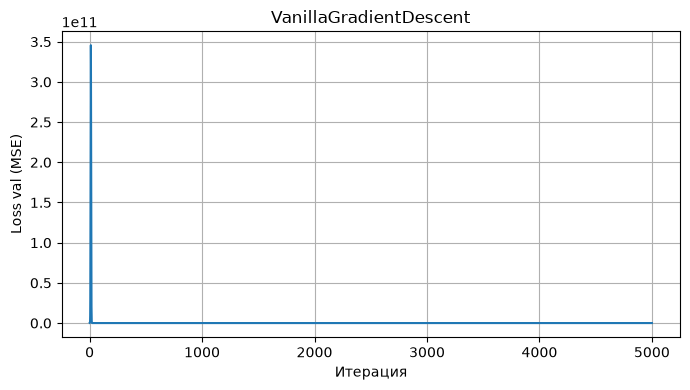

In [7]:
show_result("VanillaGradientDescent")

#### 6. Исследование StochasticGradientDescent

1. Для каждого шага lyamda в логарифмической сетке: 10^-5, … , 1:

обучите StochasticGradientDescent с шагом lyamda на train, вычислите R_train ^ 2 и Loss_train;

протестируйте StochasticGradientDescent с шагом lyamda на val, вычислите Loss_val.

2. Найдите лучший шаг lyamda по минимальному Loss_val.

In [8]:
search("StochasticGradientDescent")

Лучший шаг: 0.1


,lyamda,R2 train,Loss train,Loss val
0,0.00001,0.005146,6.054922e+07,5.508346e+07
1,0.00010,0.049632,5.784169e+07,5.265820e+07
2,0.00100,0.354904,3.926207e+07,3.607936e+07
3,0.01000,0.675501,1.974978e+07,2.094329e+07
4,0.10000,0.719558,1.706838e+07,1.990830e+07
5,1.00000,-1.117997,1.289064e+08,1.584405e+08


#### 7. Тестирование StochasticGradientDescent с лучшим шагом

Выведите (R_test)^2 и Loss_test.

In [9]:
test_model("StochasticGradientDescent")

R2 test: 0.6460594274844722
Loss test: 24682925.01218615


#### 8. Вывод по StochasticGradientDescent

1. Выведите на экран: лучший шаг, loss_train (для лучшего шага), loss_test, r^2_train (для лучшего шага), число итераций на val;

2. Отобразите график зависимости Loss_val для лучшего шага от числа итераций.

Лучший шаг: 0.1
Loss train: 17068378.359494716
Loss test: 24682925.01218615
R2 train: 0.7195580095879411
Число итераций с оценкой на val: 5000


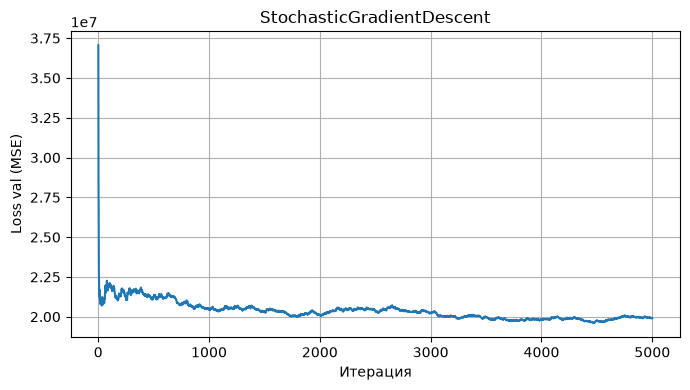

In [10]:
show_result("StochasticGradientDescent")

#### 9. Исследование SAGDescent

1. Для каждого шага lyamda в логарифмической сетке: 10^-5, … , 1:

обучите SAGDescent с шагом lyamda на train, вычисляем R^2_train и Loss_train;

протестируйте SAGDescent с шагом lyamda на val, вычисляем Loss_val.

2. Найдите наилучший шаг lyamda по минимальному Loss_val.

In [11]:
search("SAGDescent")

Лучший шаг: 1.0


,lyamda,R2 train,Loss train,Loss val
0,0.00001,0.003284,6.066254e+07,5.518508e+07
1,0.00010,0.032176,5.890409e+07,5.361047e+07
2,0.00100,0.263690,4.481361e+07,4.100018e+07
3,0.01000,0.664807,2.040063e+07,2.115376e+07
4,0.10000,0.709942,1.765363e+07,2.039529e+07
5,1.00000,0.741538,1.573065e+07,2.000369e+07


#### 10. Тестирование SAGDescent с лучшим шагом

Выведите (R_test)^2 и Loss_test.

In [12]:
test_model("SAGDescent")

R2 test: 0.6060028508829268
Loss test: 27476369.881967105


#### 11. Вывод по SAGDescent

1. Выведите на экран: лучший шаг, loss_train (для лучшего шага), loss_test, r^2_train (для лучшего шага), число итераций на val;

2. Отобразите график зависимости Loss_val для лучшего шага от числа итераций.

Лучший шаг: 1.0
Loss train: 15730647.365190815
Loss test: 27476369.881967105
R2 train: 0.7415375986723253
Число итераций с оценкой на val: 5000


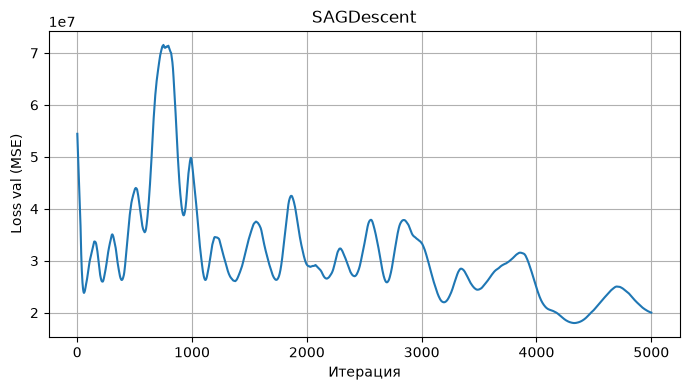

In [13]:
show_result("SAGDescent")

#### 12. Исследование MomentumDescent

1. Для каждого шага lyamda в логарифмической сетке: 10^-5, … , 1:

обучите MomentumDescent с шагом lyamda на train, вычисляем R^2_train и Loss_train;

протестируйте MomentumDescent с шагом lyamda на val, вычисляем Loss_val.

2. Найдите наилучший шаг lyamda по минимальному Loss_val.

In [14]:
search("MomentumDescent")

Лучший шаг: 1.0


,lyamda,R2 train,Loss train,Loss val
0,0.00001,0.049219,5.786683e+07,5.268181e+07
1,0.00010,0.353061,3.937425e+07,3.617088e+07
2,0.00100,0.674671,1.980031e+07,2.091152e+07
3,0.01000,0.719408,1.707753e+07,1.984668e+07
4,0.10000,0.774371,1.373231e+07,1.706890e+07
5,1.00000,0.799262,1.221737e+07,1.677847e+07


#### 13. Тестирование MomentumDescent с лучшим шагом

Выведите (R_test)^2 и Loss_test.

In [15]:
test_model("MomentumDescent")

R2 test: 0.5849576949429613
Loss test: 28944006.107574277


#### 14. Вывод по MomentumDescent

1. Выведите на экран: лучший шаг, loss_train (для лучшего шага), loss_test, r^2_train (для лучшего шага), число итераций на val;

2. Отобразите график зависимости Loss_val для лучшего шага от числа итераций.

Лучший шаг: 1.0
Loss train: 12217374.552456055
Loss test: 28944006.107574277
R2 train: 0.799262427575935
Число итераций с оценкой на val: 5000


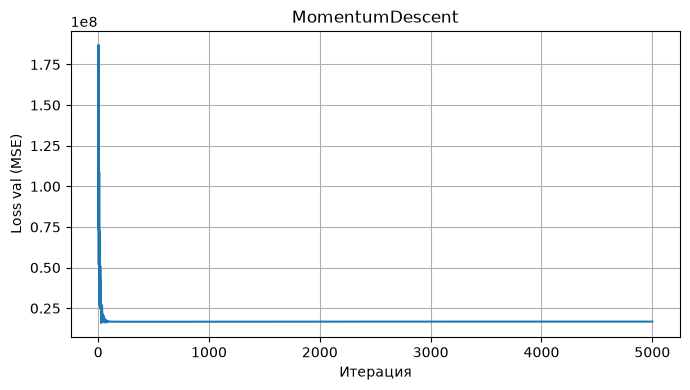

In [16]:
show_result("MomentumDescent")

#### 15. Исследование Adam

1. Для каждого шага lyamda в логарифмической сетке: 10^-5, … , 1:

обучите Adam с шагом lyamda на train, вычисляем R^2_train и Loss_train;

протестируйте Adam с шагом lyamda на val, вычисляем Loss_val.

2. Найдите наилучший шаг lyamda по минимальному Loss_val.

In [17]:
search("Adam")

Лучший шаг: 0.01


,lyamda,R2 train,Loss train,Loss val
0,0.00001,0.008678,6.033426e+07,5.486127e+07
1,0.00010,0.083373,5.578813e+07,5.061315e+07
2,0.00100,0.544949,2.769551e+07,2.577876e+07
3,0.01000,0.795366,1.245450e+07,1.758104e+07
4,0.10000,0.802369,1.202827e+07,1.800336e+07
5,1.00000,0.802369,1.202827e+07,1.851860e+07


#### 16. Тестирование Adam с лучшим шагом

Выведите (R_test)^2 и Loss_test.

In [18]:
test_model("Adam")

R2 test: 0.5927851143102882
Loss test: 28398141.574696552


#### 17. Вывод по Adam

1. Выведите на экран: лучший шаг, loss_train (для лучшего шага), loss_test, r^2_train (для лучшего шага), число итераций на val;

2. Отобразите график зависимости Loss_val для лучшего шага от числа итераций.

Лучший шаг: 0.01
Loss train: 12454496.309729949
Loss test: 28398141.574696552
R2 train: 0.795366398546153
Число итераций с оценкой на val: 5000


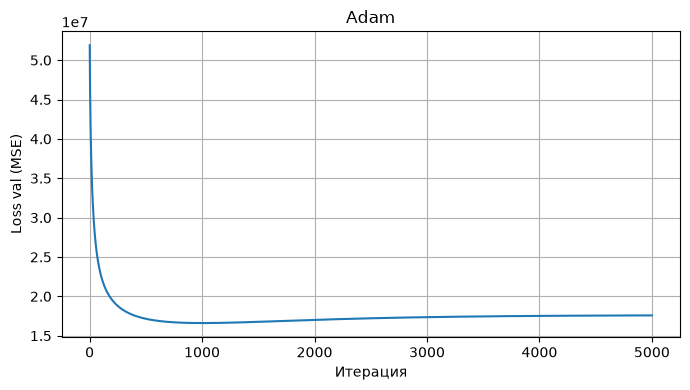

In [19]:
show_result("Adam")

#### 18. Постройте сравнительную таблицу методов

Таблица показана в лекции (таб. 2)

,Метод,Лучший шаг,Loss train,Loss val,Loss test,R2 train,R2 test,Итерации
0,VanillaGradientDescent,1.00,1.373414e+07,1.707195e+07,2.645872e+07,0.774341,0.620595,5000
1,StochasticGradientDescent,0.10,1.706838e+07,1.990830e+07,2.468293e+07,0.719558,0.646059,5000
2,SAGDescent,1.00,1.573065e+07,2.000369e+07,2.747637e+07,0.741538,0.606003,5000
3,MomentumDescent,1.00,1.221737e+07,1.677847e+07,2.894401e+07,0.799262,0.584958,5000
4,Adam,0.01,1.245450e+07,1.758104e+07,2.839814e+07,0.795366,0.592785,5000


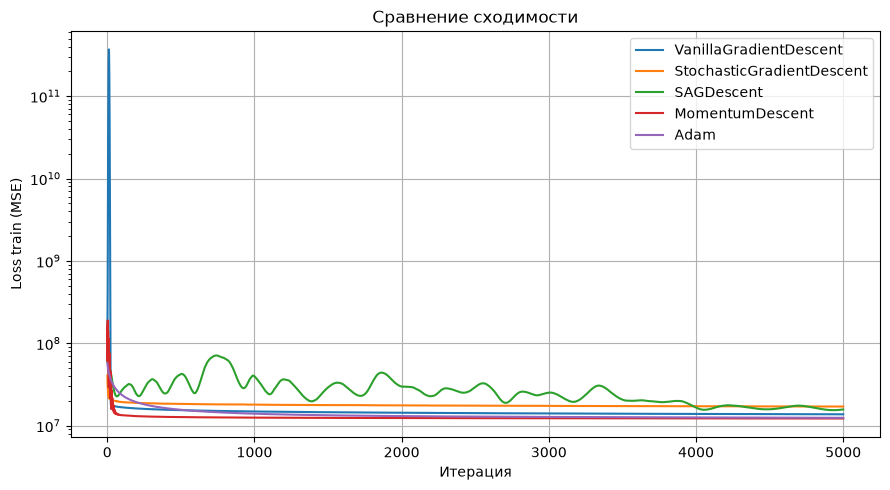

In [20]:
rows = []
for method, model in best_models.items():
    rows.append({
        "Метод": method,
        "Лучший шаг": model["lyamda"],
        "Loss train": model["train_history"][-1],
        "Loss val": model["val_history"][-1],
        "Loss test": model["Loss test"],
        "R2 train": r2_score(y_train, predict(model, X_train)),
        "R2 test": model["R2 test"],
        "Итерации": len(model["train_history"])
    })
comparison = pd.DataFrame(rows)
display(comparison)

plt.figure(figsize=(9, 5))
for method, model in best_models.items():
    plt.plot(np.arange(1, max_iter + 1), model["train_history"], label=method)
plt.xlabel("Итерация")
plt.ylabel("Loss train (MSE)")
plt.yscale("log")
plt.title("Сравнение сходимости")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#### 19. Сделайте вывод о том, какой метод и какой шаг в итоге самые оптимальные, обратите внимание на R^2, подумайте на что он влияет.

In [21]:
best = comparison.loc[comparison["Loss val"].idxmin()]
best_test = comparison.loc[comparison["Loss test"].idxmin()]
print(f"Выбор по val: {best['Метод']}, шаг {best['Лучший шаг']:g}.")
print(f"Его R2 test = {best['R2 test']:.3f}, RMSE test = {np.sqrt(best['Loss test']):.2f}.")
print(f"Минимальный Loss test в итоговом сравнении: {best_test['Метод']}.")

Выбор по val: MomentumDescent, шаг 1.
Его R2 test = 0.585, RMSE test = 5379.96.
Минимальный Loss test в итоговом сравнении: StochasticGradientDescent.


По минимальной Loss val лучший метод Momentum с шагом 1. А по минимальному Loss test SGD с шагом 0,1. R2 показывает качество прогноза. Чем выше R2 и ниже MSE на новых данных тем лучше качество. R2 не влияет на обучение.